## Model Development
### DSCI 403
#### Clara Pugh and Chandler Bergstrom

This notebook loads in preprocessed data saved using preprocessing.ipynb, and begins to develop models to predict future data

*to see all datafiles and previous notebooks related to this project, visit the github: https://github.com/claranp/DSCI-403-Final-Project/settings

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

First, we will load in the data we saved from the preprocessing section:
- full_df will be the full clean dataframe
- surface_df will be the surface temperatures only, with one row per ARGO profile
- sst_df will be the raw satellite temp data, for use while plotting

In [14]:
# load in the preprocessed data that we saved
full_df = pd.read_csv('clean_data_gulfstream_jan_2023.csv')
full_df['TIME'] = pd.to_datetime(full_df['TIME'])

surface_df = pd.read_csv('clean_SURFACE_data_gulfstream_jan_2023.csv')
surface_df['TIME'] = pd.to_datetime(surface_df['TIME'])

# as well as the full SST dataframe
sst_df = pd.read_csv('SST_only_gulfstream_jan_2023_not_clean.csv')

full_df.head()

,index,N_PROF,N_LEVELS,CYCLE_NUMBER,DATA_MODE,DIRECTION,PLATFORM_NUMBER,PRES,PRES_ERROR,PSAL,PSAL_ERROR,TEMP,TEMP_ERROR,LATITUDE,LONGITUDE,TIME,matched_sst,match_dist_km,TEMP_MINUS_SST,MONTH_DAY
0,0,0,0,220,D,A,4903258,1.08,2.4,32.7404,0.01,6.448,0.002,42.82596,-52.65462,2023-01-01 02:16:37,9.15,48.544783,-2.702000,01-01
1,1,0,1,220,D,A,4903258,2.04,2.4,32.7411,0.01,6.454,0.002,42.82596,-52.65462,2023-01-01 02:16:37,9.15,48.544783,-2.696000,01-01
2,2,0,2,220,D,A,4903258,2.96,2.4,32.7431,0.01,6.470,0.002,42.82596,-52.65462,2023-01-01 02:16:37,9.15,48.544783,-2.680000,01-01
3,3,0,3,220,D,A,4903258,3.96,2.4,32.7452,0.01,6.458,0.002,42.82596,-52.65462,2023-01-01 02:16:37,9.15,48.544783,-2.691999,01-01
4,4,0,4,220,D,A,4903258,5.04,2.4,32.7467,0.01,6.459,0.002,42.82596,-52.65462,2023-01-01 02:16:37,9.15,48.544783,-2.691000,01-01


## Machine Learning Models

After exploring the relationship between ARGO float measurements and satellite sea-surface temperature, we can use machine learning algorithms to possibly predict the difference between the two temperature measurements.

Our target variable is `DIFF`, which represents the difference between ARGO surface temperature and satellite SST. We will use satellite SST, latitude, and longitude as predictor variables.

We will compare three regression algorithms: ridge regression, random forest regression, and gradient boosting regression. These models allow us to compare a relatively simple linear model against more complex nonlinear models.

We will evaluate the models using mean absolute error (MAE), root mean squared error (RMSE), and r-squared (R²).

In [15]:
# variables in use
features = ['SST', 'LAT', 'LON']
target = 'DIFF'

# remove rows w/ missing values 
model_df = surface_df[features + [target, 'PLATFORM_NUMBER']].dropna().copy()

# define predictor variables + target variable
X = model_df[features]
y = model_df[target]

# use float ID to group observations 
groups = model_df['PLATFORM_NUMBER']

print("Number of observations:", len(model_df))
print("Number of unique ARGO floats:", groups.nunique())
print("\nPredictor variables:", features)
print("Target variable:", target)

Number of observations: 215
Number of unique ARGO floats: 74

Predictor variables: ['SST', 'LAT', 'LON']
Target variable: DIFF


In [16]:
# splitting data into training and testing sets 

# split observations by ARGO float
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training floats:", groups_train.nunique())
print("Testing floats:", groups.iloc[test_idx].nunique())

Training observations: 175
Testing observations: 40
Training floats: 59
Testing floats: 15


In [17]:
# ridge regression- linear model w/ regularization

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

# test different regularization strengths
ridge_params = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

# grouped cross-validation
n_splits = min(5, groups_train.nunique())
group_cv = GroupKFold(n_splits=n_splits)

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=group_cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_search.fit(X_train, y_train, groups=groups_train)

ridge_model = ridge_search.best_estimator_

print("Best Ridge parameters:", ridge_search.best_params_)
print("Best cross-validation RMSE:", -ridge_search.best_score_)

Best Ridge parameters: {'model__alpha': 100}
Best cross-validation RMSE: 1.0312935279708442


In [18]:
# rando forest regression
rf_model = RandomForestRegressor(random_state=42)

# hyperparameter combinations to test
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4]
}

rf_search = GridSearchCV(
    rf_model,
    rf_params,
    cv=group_cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

rf_search.fit(X_train, y_train, groups=groups_train)

rf_model = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best cross-validation RMSE:", -rf_search.best_score_)

Best Random Forest parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 200}
Best cross-validation RMSE: 0.9954047131375516


In [19]:
# gradient boosting regression
gb_model = GradientBoostingRegressor(random_state=42)

# hyperparameter combos to test
gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [1, 2, 3],
    'subsample': [0.8, 1.0]
}

gb_search = GridSearchCV(
    gb_model,
    gb_params,
    cv=group_cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

gb_search.fit(X_train, y_train, groups=groups_train)

gb_model = gb_search.best_estimator_

print("Best Gradient Boosting parameters:", gb_search.best_params_)
print("Best cross-validation RMSE:", -gb_search.best_score_)

Best Gradient Boosting parameters: {'learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 100, 'subsample': 1.0}
Best cross-validation RMSE: 0.994407394979881


In [20]:
# generate predictions using testing dataset
predictions = {
    'Ridge Regression': ridge_model.predict(X_test),
    'Random Forest': rf_model.predict(X_test),
    'Gradient Boosting': gb_model.predict(X_test)
}

# calc evaluation metrics
results = []

for name, prediction in predictions.items():

    mae = mean_absolute_error(y_test, prediction)
    rmse = np.sqrt(mean_squared_error(y_test, prediction))
    r2 = r2_score(y_test, prediction)

    results.append({
        'Model': name,
        'MAE (°C)': mae,
        'RMSE (°C)': rmse,
        'R²': r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

            Model  MAE (°C)  RMSE (°C)      R²
 Ridge Regression    0.4920     0.7673  0.1445
    Random Forest    0.5161     0.8549 -0.0618
Gradient Boosting    0.4602     0.7496  0.1836


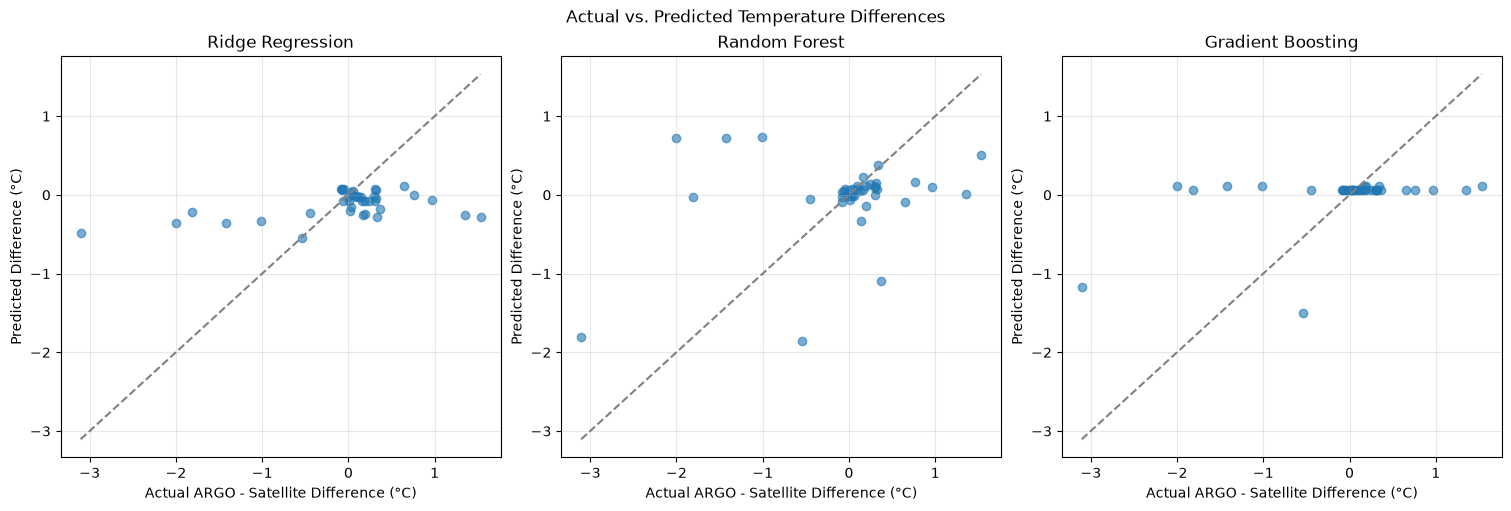

In [21]:
# compare actual and predicted temp differences

fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')

for ax, (name, prediction) in zip(axes, predictions.items()):

    ax.scatter(y_test, prediction, alpha=0.6)

    # reference line: 'perfect predictions'
    low = min(y_test.min(), prediction.min())
    high = max(y_test.max(), prediction.max())

    ax.plot([low, high], [low, high], '--', color='grey')

    ax.set_title(name)
    ax.set_xlabel('Actual ARGO - Satellite Difference (°C)')
    ax.set_ylabel('Predicted Difference (°C)')
    ax.grid(alpha=0.3)

fig.suptitle('Actual vs. Predicted Temperature Differences')
plt.show()